In [28]:
import optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from catboost import CatBoostClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report
)


In [29]:
def data_info(data):

    """
    This function returns a DataFrame containing the summary information for each column
    """

    Names=[col for col in data]
    data_types=[data[col].dtype for col in data.columns]
    top_10_unique_values=[data[col].value_counts().head(10).index.to_list() for col in data.columns]
    nunique_values=[data[col].nunique() for col in data.columns]
    nulls=[data[col].isnull().sum() for col in data.columns]
    percent_of_Nulls= [data[col].isnull().sum()/len(data)*100 for col in data.columns]
    duplicates=data.duplicated().sum()


    info_df=pd.DataFrame({'Name':Names,
                          'Data_Type':data_types,
                          'Top_10_Unique_Values':top_10_unique_values,
                          'Nunique_Values':nunique_values,
                          'Nulls':nulls,
                          'Percent_of_Nulls':percent_of_Nulls,
                          'Duplicates':duplicates})
    return info_df

In [30]:
train_df = pd.read_csv("preprocessed_train_pca.csv")
test_df = pd.read_csv("preprocessed_test_pca.csv")

In [31]:
data_info(train_df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,PC01,float64,"[-0.3807000348447774, 2.5678421540697283, 0.07...",43335,0,0.0,4540
1,PC02,float64,"[7.09709923799542, 5.933796459126948, 7.564720...",43335,0,0.0,4540
2,PC03,float64,"[-0.4433470819902003, -2.963392633242212, -0.4...",43335,0,0.0,4540
3,PC04,float64,"[2.517459169051467, -3.1871496057192825, 2.453...",43335,0,0.0,4540
4,PC05,float64,"[1.540804961895072, -4.277464325500423, 1.9950...",43335,0,0.0,4540
5,PC06,float64,"[-0.7956875891268457, -4.417707498169771, -0.8...",43335,0,0.0,4540
6,PC07,float64,"[0.6415305056840194, -1.7810833188189037, 0.43...",43334,0,0.0,4540
7,PC08,float64,"[-0.0229196443167372, -0.3189250012478343, 0.0...",43335,0,0.0,4540
8,PC09,float64,"[-1.470524058424849, -1.8031224841234064, -1.2...",43335,0,0.0,4540
9,PC10,float64,"[0.8362002014527632, -0.2555122028012979, 0.03...",43334,0,0.0,4540


In [32]:
data_info(test_df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,PC01,float64,"[1.4258368197888196, 1.6871986060928967, -4.32...",11959,0,0.0,11
1,PC02,float64,"[-4.342656233365043, -4.3578498545064654, 1.27...",11959,0,0.0,11
2,PC03,float64,"[-5.101145947445104, -2.672443110314275, -0.43...",11959,0,0.0,11
3,PC04,float64,"[0.8224923180163427, -0.3991876967493648, 0.69...",11959,0,0.0,11
4,PC05,float64,"[-0.0989809473199084, 1.8647632523114044, 1.00...",11959,0,0.0,11
5,PC06,float64,"[-0.3026188824516937, 1.0320795193295949, 0.66...",11959,0,0.0,11
6,PC07,float64,"[0.059924706331041, 1.6766950892994483, -0.013...",11959,0,0.0,11
7,PC08,float64,"[3.816085258041243, 2.013980152933601, 0.05293...",11959,0,0.0,11
8,PC09,float64,"[1.025021703390861, -0.0601306088093717, -2.42...",11959,0,0.0,11
9,PC10,float64,"[0.5233062272199646, -0.3463994466999625, 1.26...",11959,0,0.0,11


In [33]:
train_df = train_df.drop_duplicates()
test_df = test_df.drop_duplicates()

In [34]:
X = train_df.drop(columns=["target"])
y = train_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

In [35]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [36]:
print("=" * 65)
print("DATA SUMMARY")
print("=" * 65)
print("Training samples  :", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples      :", len(X_test))
print("Features          :", X_train.shape[1])

DATA SUMMARY
Training samples  : 34668
Validation samples: 8667
Test samples      : 11959
Features          : 25


In [37]:

print("=" * 50)
print("CHECKING DATA")
print("=" * 50)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)


CHECKING DATA
X_train: (34668, 25)
X_val  : (8667, 25)
X_test : (11959, 25)
y_train: (34668,)
y_val  : (8667,)
y_test : (11959,)


#  OPTUNA HYPERPARAMETER OPTIMIZATION

In [38]:
def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 600, 1500),
        'depth': trial.suggest_int('depth', 5, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 15),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'border_count': trial.suggest_categorical('border_count', [128, 254]),
        'eval_metric': 'AUC',
        'random_seed': 42,
        'verbose': 0
    }
    
    model = CatBoostClassifier(**params)
    model.fit(
        X_train, y_train,
        eval_set=(X_val, y_val),
        early_stopping_rounds=60,
        verbose=False
    )
    
    preds_proba = model.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, preds_proba)
    
    print(f" [Trial {trial.number:02d}] Validation AUC: {val_auc:.6f}")
    return val_auc

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=35, timeout=800)

print("\n" + "="*65)
print(" OPTIMIZATION COMPLETED! COPY THESE BEST PARAMETERS:")
print("="*65)
for k, v in study.best_params.items():
    print(f"'{k}': {v},")
print(f" Best Validation AUC Score: {study.best_value:.6f}")
print("="*65)

[I 2026-10-16 12:05:01,383] A new study created in memory with name: no-name-1b894d27-2efd-4845-9fc3-6f250d582534
[I 2026-10-16 12:05:21,978] Trial 0 finished with value: 0.9995835314484441 and parameters: {'iterations': 1316, 'depth': 9, 'learning_rate': 0.030667930521921734, 'l2_leaf_reg': 11.028979234110976, 'random_strength': 0.204615282051814, 'bagging_temperature': 0.8273146883728247, 'subsample': 0.968388013333155, 'border_count': 254}. Best is trial 0 with value: 0.9995835314484441.


 [Trial 00] Validation AUC: 0.999584


[I 2026-10-16 12:05:27,186] Trial 1 finished with value: 0.999582411048805 and parameters: {'iterations': 825, 'depth': 7, 'learning_rate': 0.0559310767493378, 'l2_leaf_reg': 13.517934483464016, 'random_strength': 0.29411062413757827, 'bagging_temperature': 0.10623014004108311, 'subsample': 0.9281428167090202, 'border_count': 128}. Best is trial 0 with value: 0.9995835314484441.


 [Trial 01] Validation AUC: 0.999582


[I 2026-10-16 12:06:35,263] Trial 2 finished with value: 0.9995950022066538 and parameters: {'iterations': 1167, 'depth': 10, 'learning_rate': 0.013467803810987541, 'l2_leaf_reg': 12.85305053195777, 'random_strength': 1.0713448010620448, 'bagging_temperature': 0.5782958985391456, 'subsample': 0.7975177299347628, 'border_count': 254}. Best is trial 2 with value: 0.9995950022066538.


...

 [Trial 32] Validation AUC: 0.999712


[I 2026-10-16 12:11:05,677] Trial 33 finished with value: 0.9996526227595208 and parameters: {'iterations': 911, 'depth': 5, 'learning_rate': 0.02770039562602947, 'l2_leaf_reg': 1.4560162077440397, 'random_strength': 9.576938425888283, 'bagging_temperature': 0.9261027417293966, 'subsample': 0.9333226103907227, 'border_count': 128}. Best is trial 29 with value: 0.99973846671282.


 [Trial 33] Validation AUC: 0.999653


[I 2026-10-16 12:11:09,862] Trial 34 finished with value: 0.9996679348879217 and parameters: {'iterations': 953, 'depth': 5, 'learning_rate': 0.06304986318077098, 'l2_leaf_reg': 1.2090643203619442, 'random_strength': 8.154148383070162, 'bagging_temperature': 0.8994970497868655, 'subsample': 0.8421016439372823, 'border_count': 128}. Best is trial 29 with value: 0.99973846671282.


 [Trial 34] Validation AUC: 0.999668

 OPTIMIZATION COMPLETED! COPY THESE BEST PARAMETERS:
'iterations': 902,
'depth': 5,
'learning_rate': 0.050195033252163734,
'l2_leaf_reg': 4.865453139012461,
'random_strength': 9.557879475625695,
'bagging_temperature': 0.9998118981426584,
'subsample': 0.8473129642420563,
'border_count': 128,
 Best Validation AUC Score: 0.999738


#  FINAL MODEL TRAINING 

In [41]:
best_params = {
    'iterations': 902,          
    'depth': 5,                  
    'learning_rate': 0.050195033252163734,       
    'l2_leaf_reg': 4.865453139012461,          
    'random_strength': 9.557879475625695,      
    'bagging_temperature': 0.9998118981426584,  
    'subsample': 0.8473129642420563,           
    'border_count': 128,         
    'eval_metric': 'AUC',
    'random_seed': 42
}


final_model = CatBoostClassifier(
    **best_params,
    verbose=100  
)

final_model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    early_stopping_rounds=60
)

print("\n Final Model Training Completed Successfully!")

0:	test: 0.9799641	best: 0.9799641 (0)	total: 10.1ms	remaining: 9.07s
100:	test: 0.9992220	best: 0.9992220 (100)	total: 1.08s	remaining: 8.54s
200:	test: 0.9995364	best: 0.9995364 (200)	total: 2.19s	remaining: 7.64s
300:	test: 0.9996550	best: 0.9996562 (293)	total: 3.25s	remaining: 6.49s
400:	test: 0.9996790	best: 0.9996833 (391)	total: 4.34s	remaining: 5.42s
500:	test: 0.9997163	best: 0.9997163 (500)	total: 5.4s	remaining: 4.32s
600:	test: 0.9997359	best: 0.9997360 (599)	total: 6.5s	remaining: 3.25s
700:	test: 0.9997373	best: 0.9997385 (669)	total: 7.44s	remaining: 2.13s
Stopped by overfitting detector  (60 iterations wait)

bestTest = 0.9997384667
bestIteration = 669

Shrink model to first 670 iterations.

 Final Model Training Completed Successfully!


In [39]:
# best_params = {
#     'iterations': 785,          
#     'depth': 6,                  
#     'learning_rate': 0.06,       
#     'l2_leaf_reg': 5,          
#     'random_strength': 2.5,      
#     'bagging_temperature': 0.2,  
#     'subsample': 0.65,           
#     'border_count': 130,         
#     'eval_metric': 'AUC',
#     'random_seed': 42
# }


# final_model = CatBoostClassifier(
#     **best_params,
#     verbose=100  
# )

# final_model.fit(
#     X_train, y_train,
#     eval_set=(X_val, y_val),
#     early_stopping_rounds=60
# )

# print("\n Final Model Training Completed Successfully!")

             Metric  Training Set  Test Set
          AUC Score      0.999918  0.999677
           Accuracy      0.998529  0.996154
F1-Score (Weighted)      0.998529  0.996154
-----------------------------------------------------------------

 Detailed Classification Report (Test Set):

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      5671
           1       1.00      0.99      1.00      6288

    accuracy                           1.00     11959
   macro avg       1.00      1.00      1.00     11959
weighted avg       1.00      1.00      1.00     11959



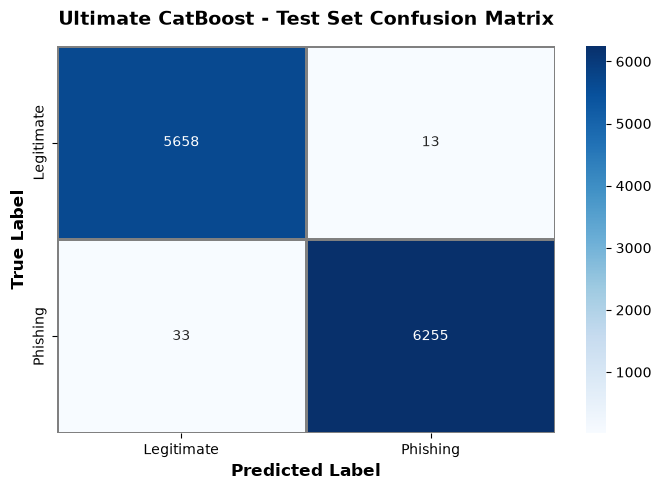

In [42]:
train_probs = final_model.predict_proba(X_train)[:, 1]
train_preds = final_model.predict(X_train)

test_probs = final_model.predict_proba(X_test)[:, 1]
test_preds = final_model.predict(X_test)
df_performance = pd.DataFrame({
    "Metric": ["AUC Score", "Accuracy", "F1-Score (Weighted)"],
    "Training Set": [
        roc_auc_score(y_train, train_probs),
        accuracy_score(y_train, train_preds),
        f1_score(y_train, train_preds, average='weighted')
    ],
    "Test Set": [
        roc_auc_score(y_test, test_probs),
        accuracy_score(y_test, test_preds),
        f1_score(y_test, test_preds, average='weighted')
    ]
})

print(df_performance.to_string(index=False))
print("-" * 65)

print("\n Detailed Classification Report (Test Set):\n")
print(classification_report(y_test, test_preds))

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='gray',
            xticklabels=['Legitimate', 'Phishing'],
            yticklabels=['Legitimate', 'Phishing'])

plt.title('Ultimate CatBoost - Test Set Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()